# 01 — TextRank passo per passo (versione didattica)

Questo notebook segue **una sola riga** di Multi-News (un cluster di 2-3 articoli + il riassunto
umano di riferimento) e mostra, un passaggio alla volta, come **TextRank** (Mihalcea & Tarau, 2004) trasforma
il testo in un riassunto estrattivo e come lo si valuta.

A differenza di [`notebooks/01_textrank.ipynb`](../notebooks/01_textrank.ipynb),
che gira in batch su migliaia di righe e salva solo i risultati, qui l'obiettivo è **capire**:
ogni passaggio è spiegato, calcolato "a mano" quando possibile e **verificato contro la
libreria `pyAutoSummarizer`** usata nel benchmark (le `assert` garantiscono che quello che
vedi qui sia esattamente ciò che fa il codice di produzione).

## Il workflow in una figura

```
documento (2-3 articoli)
      │  1. scelta della riga
      ▼
frasi  s₀ s₁ … s_{N-1}            ← 2. suddivisione in frasi
      │
      ▼
rappresentazioni delle frasi        ← 3. embedding MiniLM
      │
      ▼
matrice di similarità N×N           ← 4-5. coseno tra tutte le coppie + heatmap
      │
      ▼
grafo pesato (nodi = frasi)         ← 6. archi = similarità
      │
      ▼
punteggi PageRank                   ← 7. centralità di ogni frase
      │
      ▼
frasi più centrali                  ← 8. selezione
      │
      ▼
riassunto estrattivo                ← 9. generazione
      │
      ▼
confronto con il riferimento        ← 10. + variante a budget di parole
      │
      ▼
ROUGE / BLEU / METEOR               ← 11. metriche
      │
      ▼
interpretazione                     ← 12.
```

## L'idea in due righe
Una frase è **importante** se è **simile a molte altre frasi importanti** (le informazioni
ripetute da più articoli sono quelle centrali). Si costruisce un grafo in cui le frasi sono nodi
e il peso di un arco è la loro similarità; PageRank — lo stesso algoritmo di Google — assegna a
ogni nodo un punteggio di centralità. In TextRank la similarità è calcolata su **sentence embedding** (vettori densi prodotti da una rete neurale, `all-MiniLM-L6-v2`).

> Il notebook gemello è [`02_lexrank_didattico.ipynb`](02_lexrank_didattico.ipynb) (LexRank): i passi 1-2 e 6-12
> sono identici, cambia solo come si rappresentano le frasi (3) e quindi la matrice (4-5).

⚠️ **Una riga non è un benchmark.** Le metriche della sezione 11 riguardano un solo esempio e
servono a capire *come si calcolano*, non a stabilire quale metodo sia migliore (per questo
esistono i notebook di benchmark su 5.610 righe).

## 0. Preparazione
Importiamo le librerie e le funzioni condivise del progetto (`summ_utils`). Il notebook si può
lanciare dalla cartella `notebooks_didattici/` o dalla radice del repository.

In [1]:
import re
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.metrics.pairwise import cosine_similarity

# radice del progetto: la cartella sopra notebooks_didattici/ (o la cwd se già alla radice)
_cwd = Path.cwd()
BASE = _cwd.parent if _cwd.name in ('notebooks_didattici', 'notebooks') else _cwd
sys.path.insert(0, str(BASE / 'notebooks'))

import summ_utils as su
from pyAutoSummarizer.base import psr

su.stile_grafici()
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 110

P = su.percorsi_standard(BASE)
print('Radice del progetto:', BASE)

C:\Users\maccu\AppData\Roaming\Python\Python312\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.6.0)/charset_normalizer (3.4.7) doesn't match a supported version!
  warnings.warn(


C:\Users\maccu\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Radice del progetto: C:\Users\maccu\OneDrive\Desktop\Master_Project


## 1. Selezione del testo di partenza
Multi-News è composto da *cluster*: ogni riga contiene **2-3 articoli** sullo stesso evento,
concatenati con il separatore `|||||`, e un **riassunto scritto da un umano** (il
*riferimento*, o *gold*). Lavoriamo sulla **split di test** (la stessa su cui il benchmark
valuta i metodi).

`ROW_ID` è l'indice globale della riga in `data/tab/complete.tab`. La riga predefinita
(**50492**) è stata scelta perché è breve (19 frasi): la matrice di similarità e il grafo
restano **leggibili**. Puoi cambiare `ROW_ID` con qualunque altra riga della split di test
(50491-56100): il resto del notebook si adatta (con documenti molto lunghi i grafici
diventano però fitti).

**`MODALITA`** sceglie come viene fissata la **lunghezza** del riassunto (TextRank/LexRank
producono solo un ordinamento delle frasi: quante prenderne è una scelta esterna):

| `MODALITA` | regola | corrisponde a |
|---|---|---|
| `'frasi'` | le prime `N_SENTENCES` (= 11) frasi per punteggio | ambito `test` del benchmark |
| `'budget'` | frasi in ordine di punteggio finché si raggiunge la lunghezza in parole del riferimento, poi tetto a 1,25× | ambito `test_budgetref` (issue #16) |

Cambiando `MODALITA` le sezioni 8-12 si adattano; le due alternative restano comunque
confrontabili nelle tabelle delle sezioni 10 e 11.

In [2]:
ROW_ID = 50492          # riga della split di test (50491-56100)
# Come si decide la LUNGHEZZA del riassunto (l'algoritmo produce solo un ordinamento di frasi):
#   'frasi'  -> le prime N_SENTENCES frasi per punteggio (benchmark ambito `test`)
#   'budget' -> frasi in ordine di punteggio fino alla lunghezza in parole del riferimento,
#               poi tetto a 1,25x (benchmark ambito `test_budgetref`, issue #16)
MODALITA = 'budget'
N_SENTENCES = 11           # usato se MODALITA == 'frasi' (mediana del corpus)
assert MODALITA in ('frasi', 'budget'), "MODALITA deve essere 'frasi' oppure 'budget'"

import csv

PRIMO_ROW_ID_TEST = 50491          # le righe di test sono 50491-56100 in complete.tab
PERCORSO_TEST = P['complete_tab'].with_name('test.tab')   # solo split test (68 MB): basta e avanza

def carica_riga_test(row_id):
    """Legge UNA riga di test. Prima da data/tab/test.tab (leggero, ideale su Colab: row_id = 50491 + indice,
    allineamento verificato con complete.tab), altrimenti da complete.tab (690 MB)."""
    problemi = []
    if PERCORSO_TEST.exists():
        try:
            with open(PERCORSO_TEST, encoding='utf-8', newline='') as f:
                lettore = csv.reader(f, delimiter='\t')
                for _ in range(su.HEADER_LINES_TAB):
                    next(lettore)
                for i, riga in enumerate(lettore):
                    if i == row_id - PRIMO_ROW_ID_TEST:
                        documento, riassunto_umano = riga          # ValueError se la riga è corrotta
                        return {'row_id': row_id, 'split': 'test', 'document': documento, 'summary': riassunto_umano}
            problemi.append(f'{PERCORSO_TEST.name}: row_id {row_id} fuori dalla split di test (50491-56100)')
        except ValueError:
            problemi.append(f'{PERCORSO_TEST.name} è incompleto o corrotto (riga con un numero di colonne inatteso)')
    else:
        problemi.append(f'{PERCORSO_TEST} non trovato')
    if P['complete_tab'].exists():
        try:
            return next(es for es in su.itera_split(P['complete_tab'], 'test') if es['row_id'] == row_id)
        except (ValueError, StopIteration):
            problemi.append(f'{P["complete_tab"].name} è incompleto o corrotto')
    else:
        problemi.append(f'{P["complete_tab"]} non trovato')
    raise RuntimeError('Impossibile leggere la riga: ' + ' | '.join(problemi) + '.\n'
        'I file .tab del repository sono su Git LFS: un `git clone` senza LFS (o un upload interrotto su Colab) '
        'dà un puntatore di pochi byte o un file troncato. Soluzioni: `git lfs pull`, oppure carica '
        'data/tab/test.tab (68 MB) in <radice>/data/tab/.')

esempio = carica_riga_test(ROW_ID)

articoli = [a.strip() for a in esempio['document'].split('|||||')]
riferimento = su.pulisci_riferimento(esempio['summary'])

print(f"row_id {ROW_ID} | split: {esempio['split']} | articoli nel cluster: {len(articoli)}")
print(f"parole nel documento: {len(esempio['document'].split())} | parole nel riferimento: {len(riferimento.split())}")
for k, a in enumerate(articoli, 1):
    print(f"\n--- Articolo {k} ({len(a.split())} parole) ---")
    print(textwrap.fill(a[:500] + ' […]', 110))
print('\n=== RIASSUNTO DI RIFERIMENTO (umano) ===')
print(textwrap.fill(riferimento, 110))

row_id 50492 | split: test | articoli nel cluster: 2
parole nel documento: 664 | parole nel riferimento: 168

--- Articolo 1 (482 parole) ---
UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, became an accidental spokesperson
for gay rights overnight on Boing Boing     It’s time to clarify a few details about the controversial “Hey
Facebook what’s SO wrong with a pic of two men kissing?” story, as it now beginning to be reported in the
mainstream media, and not always correctly.     First of all, with regards to the picture:     The photo which
was used to illustrate my first post about the John Snow Kiss-In i […]

--- Articolo 2 (181 parole) ---
|| News ||     Page 1 of 1             UPDATED: A photo of two men kissing that was posted on a Facebook page
protesting a London pub’s decision to eject a same-sex couple for kissing has been removed by the social
networking site, an error, according to a rep for the company.         "The photo in question does not vi

**Cosa abbiamo visto.** Il documento è l'unione dei 2-3 articoli; il riferimento è molto più
breve ed è scritto in modo *astratto* (riformula), mentre TextRank/LexRank possono solo
**copiare frasi intere** dal documento: per questo vengono chiamati *estrattivi*.

## 2. Suddivisione del testo in frasi
L'unità di analisi di TextRank/LexRank è la **frase**: ogni frase diventerà un nodo del grafo.
Passi, uguali a quelli del benchmark (`genera()` dei notebook 01/02):

1. il separatore `|||||` tra articoli viene sostituito da un a capo (`su.prepara_documento`),
   altrimenti resterebbe dentro le "frasi";
2. `psr.summarization(...)` spezza il testo con una **espressione regolare**: taglia dopo
   `. ! ?` seguiti da spazio, **tranne** dopo abbreviazioni (`Mr`, `Dr`, `Prof`, `St`, nomi
   dei mesi abbreviati, iniziali maiuscole come in "J. Smith"), per non spezzare "Dr. Rossi"
   in due frasi.

L'oggetto `s` conserva `s.original` (le frasi **originali**, che finiranno nel riassunto) e
`s.corpus` (le stesse frasi **pre-processate**, usate solo per calcolare il ranking — le vedremo
nella sezione 3).

In [3]:
documento = su.prepara_documento(esempio['document'])
s = psr.summarization(documento, stop_words=['en'])

frasi = s.original
N = len(frasi)
print(f'Il documento è stato diviso in N = {N} frasi (⇒ un grafo con {N} nodi e {N*(N-1)//2} possibili archi).\n')

tab_frasi = pd.DataFrame({'frase': range(N), 'parole': [len(f.split()) for f in frasi],
                          'testo': [f[:105] + ('…' if len(f) > 105 else '') for f in frasi]}).set_index('frase')
display(tab_frasi)

Il documento è stato diviso in N = 19 frasi (⇒ un grafo con 19 nodi e 171 possibili archi).



,parole,testo
frase,,
0,60,"UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, became an accidental spokesper…"
1,59,"First of all, with regards to the picture: \n \n The photo which was used to illustrate my first post about…"
2,23,I am not a regular viewer so I can’t say if the man on the right is an extra or an actual character
3,33,"This picture has itself caused scandal in the UK, as it was a gay kiss that was broadcast before the wate…"
4,21,"However, since this episode aired (October 2008) Christian now has a boyfriend and a few more gay kisses …"
5,25,"In relation to the John Snow Kiss-In event, I used this particular photo because I considered it to be qu…"
6,15,The photos I had considered using before I chose that one are much more racy
7,3,Oh the irony
8,37,"Secondly, the removal of the Facebook John Snow Kiss-In event: \n \n It turns out that the Facebook event f…"


**Cosa abbiamo visto.** Le frasi hanno lunghezze molto diverse e sono numerate `0 … N-1` nell'ordine
in cui compaiono nel documento: questi numeri sono gli **indici dei nodi** che useremo in tutti i
grafici. Nota anche che la divisione è *euristica*: titoli, didascalie o frasi senza punto finale
possono diventare "frasi" a sé.

## 3. Costruzione delle rappresentazioni testuali
### 3a. Pre-processing (solo per il ranking)
Per confrontare le frasi si lavora su una versione "pulita": **minuscole**, senza accenti, senza
punteggiatura/caratteri speciali, **senza numeri e senza stopword inglesi** (the, of, and…), che
sono frequentissime ma portano poca informazione. Questa versione è in `s.corpus`. Attenzione: è
usata **solo per calcolare i punteggi**; il riassunto finale conterrà le frasi **originali**.

In [4]:
confronto = pd.DataFrame({'originale': [f[:80] for f in frasi[:4]],
                          'pre-processata (s.corpus)': [c[:80] for c in s.corpus[:4]]})
display(confronto)
print('Frasi del corpus pre-processato:', len(s.corpus), '| frasi originali:', len(s.original))
assert len(s.corpus) == len(s.original)   # le due liste restano allineate (indice = nodo)

,originale,pre-processata (s.corpus)
0,"UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, becam",update read richard metzger married middle aged man accidental spokesperson gay
1,"First of all, with regards to the picture: \n \n The photo which was used to illus",picture photo illustrate post john snow kiss promotional british soap opera east
2,I am not a regular viewer so I can’t say if the man on the right is an extra or,regular viewer man extra actual character
3,"This picture has itself caused scandal in the UK, as it was a gay kiss that was",picture caused scandal uk gay kiss broadcast watershed led number complaints bbc


Frasi del corpus pre-processato: 19 | frasi originali: 19


### 3b. Sentence embedding (MiniLM)
TextRank (nell'implementazione di `pyAutoSummarizer`) rappresenta ogni frase con un
**embedding**: un vettore di numeri reali prodotto da una rete neurale
(`all-MiniLM-L6-v2` di *sentence-transformers*, **384 dimensioni**) addestrata perché frasi
**semanticamente vicine** abbiano vettori vicini, anche se usano parole diverse
("the firm bought X" ≈ "X was acquired by the company").

Si dà in input a MiniLM il testo *pre-processato* (`s.corpus`) e si ottiene una matrice
**N × 384**: una riga per frase.

In [5]:
from sentence_transformers import SentenceTransformer

ST_MODEL = 'all-MiniLM-L6-v2'
modello_st = SentenceTransformer(ST_MODEL, device=su.rileva_device())
s.loaded_models[ST_MODEL] = modello_st   # come nel benchmark: la libreria riusa questo modello

embeddings = modello_st.encode(s.corpus)
print('Forma della matrice degli embedding:', embeddings.shape, '(N frasi × 384 dimensioni)')
print('Embedding della frase 0 (primi 8 valori):', np.round(embeddings[0][:8], 3))
print('Norma del vettore della frase 0:', round(float(np.linalg.norm(embeddings[0])), 3),
      '(MiniLM restituisce vettori normalizzati a 1)')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3513.70it/s]

Forma della matrice degli embedding: (19, 384) (N frasi × 384 dimensioni)
Embedding della frase 0 (primi 8 valori): [-0.051  0.042 -0.023  0.079  0.02   0.055  0.018 -0.019]
Norma del vettore della frase 0: 1.0 (MiniLM restituisce vettori normalizzati a 1)


Le 384 coordinate non hanno un significato leggibile singolarmente: contano le **posizioni
relative**. Per farsene un'idea, proiettiamo gli embedding in 2 dimensioni con una **PCA**
(solo a scopo illustrativo: la similarità sarà calcolata nello spazio completo a 384
dimensioni). Frasi vicine nel grafico parlano di cose simili.

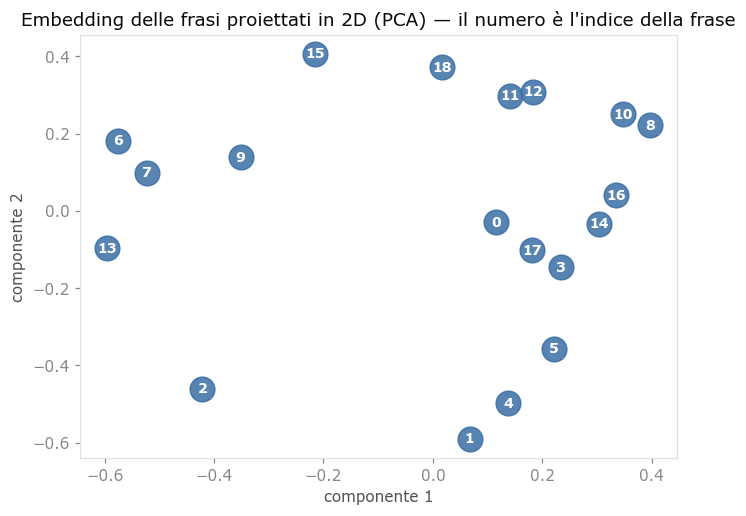

In [6]:
from sklearn.decomposition import PCA

xy = PCA(n_components=2, random_state=0).fit_transform(embeddings)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(xy[:, 0], xy[:, 1], s=260, color='#3b6ea5', alpha=.85)
for i, (x, y) in enumerate(xy):
    ax.text(x, y, str(i), ha='center', va='center', color='white', fontsize=9, fontweight='bold')
ax.set_title('Embedding delle frasi proiettati in 2D (PCA) — il numero è l\'indice della frase')
ax.set_xlabel('componente 1'); ax.set_ylabel('componente 2')
plt.show()

**Cosa abbiamo visto.** Ogni frase è ora un punto in uno spazio vettoriale. La rete neurale
ha già "digerito" il significato: la similarità tra frasi potrà essere calcolata con una
semplice operazione geometrica.

## 4. Calcolo della similarità tra frasi
Dato un vettore per ogni frase, la similarità tra due frasi è la **cosine similarity** dei loro
vettori. Calcolandola per **tutte le coppie** si ottiene una matrice quadrata **N × N**
(`sim[i, j]` = similarità tra la frase *i* e la frase *j*), simmetrica e con diagonale pari a 1.

### Cosa significa il coseno
Il **coseno** dell'angolo tra due vettori vale 1 se puntano nella stessa direzione (frasi con lo
stesso significato), 0 se sono ortogonali (nessuna relazione) e può diventare negativo se
puntano in direzioni opposte. Dipende solo dall'**angolo**, non dalla lunghezza dei vettori:
`cos(a, b) = a·b / (‖a‖ ‖b‖)`.

In [7]:
# --- a mano: coseno tra le frasi 0 e 1 -----------------------------------------------
def coseno(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

c01 = coseno(embeddings[0], embeddings[1])
print(f'cos(frase 0, frase 1) calcolato a mano  = {c01:.4f}')

# --- tutta la matrice con scikit-learn -------------------------------------------------
sim = cosine_similarity(embeddings)
print(f'cos(frase 0, frase 1) da cosine_similarity = {sim[0, 1]:.4f}')
assert np.isclose(c01, sim[0, 1])
print('\nForma della matrice di similarità:', sim.shape)
print('Simmetrica:', np.allclose(sim, sim.T), '| diagonale (frase con se stessa):', np.round(sim.diagonal()[:3], 2))

cos(frase 0, frase 1) calcolato a mano  = 0.2661
cos(frase 0, frase 1) da cosine_similarity = 0.2661

Forma della matrice di similarità: (19, 19)
Simmetrica: True | diagonale (frase con se stessa): [1. 1. 1.]


## 5. Visualizzazione della matrice di similarità
La *heatmap* rende visibile la struttura: righe e colonne sono le frasi nell'ordine del
documento, il colore indica la similarità. Cosa guardare:

- la **diagonale** è sempre 1 (ogni frase è identica a se stessa): non è informativa, quindi è **nascosta** (altrimenti schiaccia la scala dei colori);
- **blocchi chiari** fuori diagonale = gruppi di frasi che parlano della stessa cosa (spesso la
  stessa notizia riportata dai due articoli);
- **righe/colonne scure** = frasi "isolate", poco simili a tutte le altre (poco centrali).

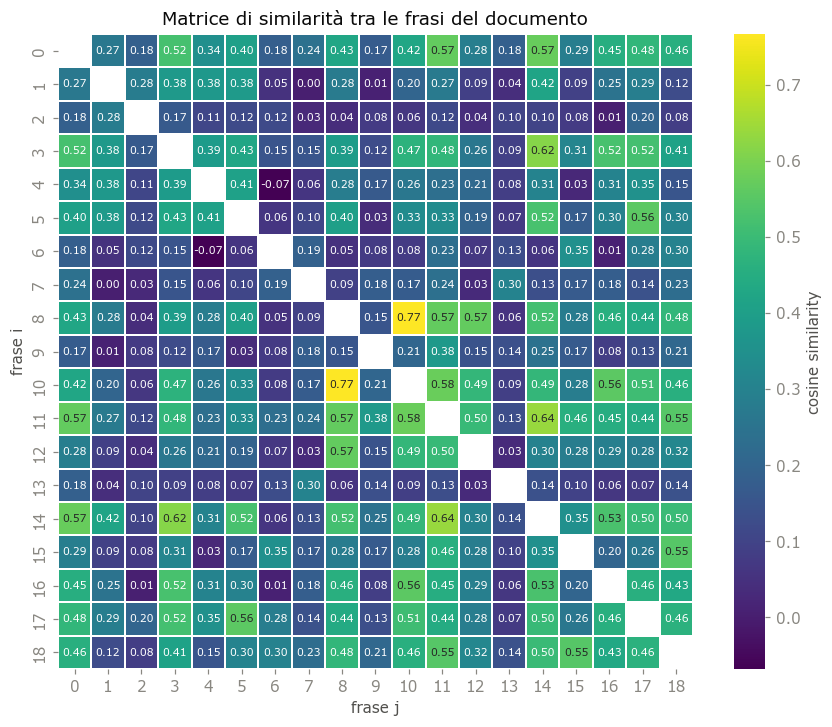

Frasi con similarità media più ALTA con le altre: [11, 14, 0]
Frasi con similarità media più BASSA con le altre: [2, 13, 6]


In [8]:
fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(sim, mask=np.eye(N, dtype=bool), annot=(N <= 22), fmt='.2f', annot_kws={'size': 7}, cmap='viridis',
            square=True, linewidths=.3, linecolor='white', cbar_kws={'label': 'cosine similarity'}, ax=ax)
ax.set_xlabel('frase j'); ax.set_ylabel('frase i')
ax.set_title('Matrice di similarità tra le frasi del documento')
plt.show()

# similarità media di ogni frase con tutte le altre (esclusa la diagonale): un'anticipazione della centralità
media_altre = (sim.sum(axis=1) - sim.diagonal()) / (N - 1)
print('Frasi con similarità media più ALTA con le altre:', [int(i) for i in np.argsort(media_altre)[::-1][:3]])
print('Frasi con similarità media più BASSA con le altre:', [int(i) for i in np.argsort(media_altre)[:3]])

**Cosa abbiamo visto.** Una frase con **riga mediamente chiara** è simile a molte altre: è
candidata a essere "centrale". Ma la similarità media è solo un'approssimazione: PageRank
(sezione 7) fa di meglio, perché pesa anche *quanto sono importanti* le frasi a cui una frase è
simile.

## 6. Costruzione del grafo delle frasi
La matrice di similarità **è** un grafo pesato: ogni **nodo** è una frase, ogni **arco** tra
*i* e *j* ha come peso `sim[i, j]`. È un grafo non orientato e *denso* (tutte le coppie sono
collegate).

Due viste:

- **A — grafo completo**, quello che l'algoritmo usa davvero: spessore e trasparenza degli
  archi proporzionali al peso; dimensione del nodo proporzionale alla **forza** (somma dei
  pesi degli archi incidenti).
- **B — solo gli archi più forti** (sopra il 75° percentile): è una semplificazione **solo
  visiva**, per vedere i cluster. Non viene usata nel calcolo.

Archi totali: 171 | peso medio: 0.266 | soglia (75° percentile): 0.416


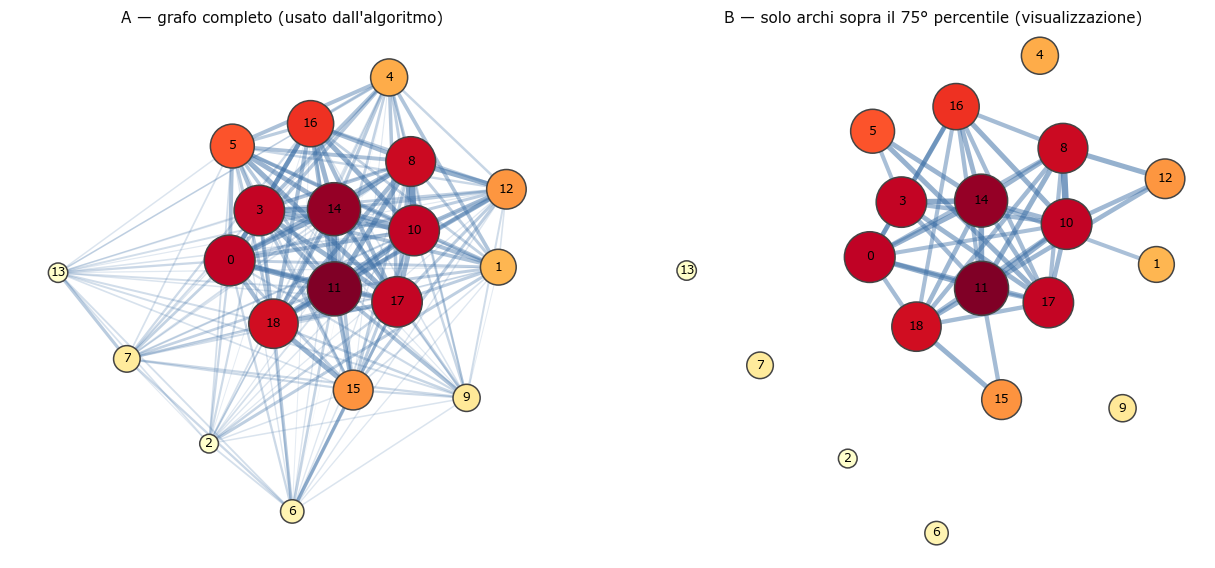

In [9]:
G = nx.Graph()
G.add_nodes_from(range(N))
for i in range(N):
    for j in range(i + 1, N):
        G.add_edge(i, j, weight=float(sim[i, j]))

forza = np.array([sum(d['weight'] for _, _, d in G.edges(i, data=True)) for i in range(N)])
pos = nx.spring_layout(G, weight='weight', seed=42, k=1.4 / np.sqrt(N), iterations=200)

pesi = np.array([d['weight'] for _, _, d in G.edges(data=True)])
soglia = np.percentile(pesi, 75)
print(f'Archi totali: {G.number_of_edges()} | peso medio: {pesi.mean():.3f} | soglia (75° percentile): {soglia:.3f}')

fig, assi = plt.subplots(1, 2, figsize=(14, 6.2))
for ax, titolo, soloforti in zip(assi, ['A — grafo completo (usato dall\'algoritmo)',
                                         'B — solo archi sopra il 75° percentile (visualizzazione)'], [False, True]):
    archi = [(u, v) for u, v, d in G.edges(data=True) if (d['weight'] >= soglia or not soloforti)]
    w = np.array([G[u][v]['weight'] for u, v in archi])
    wn = (w - pesi.min()) / (pesi.max() - pesi.min() + 1e-12)
    nx.draw_networkx_edges(G, pos, edgelist=archi, width=0.3 + 4 * wn, alpha=0.08 + 0.6 * wn, edge_color='#3b6ea5', ax=ax)
    nx.draw_networkx_nodes(G, pos, node_size=150 + 1100 * (forza - forza.min()) / (np.ptp(forza) + 1e-12),
                           node_color=forza, cmap='YlOrRd', edgecolors='#444', ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
    ax.set_title(titolo, fontsize=10); ax.axis('off')
plt.show()

**Cosa abbiamo visto.** I nodi più grandi/scuri sono quelli con più "peso" attorno: le frasi
che condividono contenuto con molte altre. Nella vista B emergono i *gruppi* di frasi
strettamente legate. PageRank sfrutta proprio questa struttura.

## 7. Calcolo dei punteggi: PageRank
**Intuizione.** Un "navigatore casuale" parte da una frase e, a ogni passo, salta a un'altra
frase con probabilità proporzionale al peso dell'arco. Dopo molti passi, la frazione di tempo
passata su ciascuna frase è il suo **punteggio**: le frasi collegate fortemente a molte altre
frasi (a loro volta ben collegate) sono visitate più spesso.

**Formula** (per la frase *i*, con fattore di smorzamento `d = 0.85`):

`PR(i) = (1 − d)/N  +  d · Σⱼ  [ w(j,i) / Σₖ w(j,k) ] · PR(j)`

Il termine `(1 − d)/N` rappresenta il "teletrasporto" (con probabilità 1−d il navigatore salta
a una frase a caso), il secondo termine il passaggio lungo gli archi.

**Come lo implementa `pyAutoSummarizer`** (funzione `page_rank`, riscritta qui passo per passo):

1. **min-max** della matrice di similarità: `(M − min) / (max − min)` ⇒ valori in [0, 1];
2. **normalizzazione per colonna**: ogni colonna divisa per la propria somma ⇒ ogni colonna è
   una distribuzione di probabilità (da dove si salta);
3. matrice di transizione `M_T = d · M_N + (1 − d)/N`;
4. si parte da `V = 1/N` per ogni frase e si ripete `V ← M_T · V` per **1000 iterazioni**.

Dettagli da conoscere: la libreria **non usa un criterio di convergenza** (fa sempre 1000
iterazioni) e usa il grafo **denso** pesato, senza soglie.

In [10]:
D = 0.85
N_ITER = 1000

def pagerank_passo_passo(M, iterazioni=N_ITER, d=D):
    """Stessa logica di psr.summarization.page_rank, ma conserva la storia delle iterazioni."""
    n = len(M)
    eps = np.finfo(float).eps
    M_minmax = (M - M.min()) / (M.max() - M.min() + eps)            # 1. min-max
    M_col = M_minmax / (M_minmax.sum(axis=0) + eps)                  # 2. colonne = probabilità
    M_T = d * M_col + (1 - d) / n                                    # 3. smorzamento + teletrasporto
    V = np.full(n, 1 / n)                                            # 4. partenza uniforme
    storia = [V.copy()]
    for _ in range(iterazioni):
        V = M_T @ V
        storia.append(V.copy())
    return V, np.array(storia), M_minmax, M_col

rank_manuale, storia, M_minmax, M_col = pagerank_passo_passo(sim)

print('Dopo la normalizzazione per colonna, la somma di ogni colonna è', np.round(M_col.sum(axis=0)[:3], 3), '… (=1)')
print('Punteggi: somma =', round(float(rank_manuale.sum()), 4), '| min =', round(float(rank_manuale.min()), 4),
      '| max =', round(float(rank_manuale.max()), 4))

# verifica contro la libreria usata nel benchmark
rank = s.summ_text_rank(model=ST_MODEL)
assert np.allclose(rank_manuale, rank, atol=1e-10), 'il PageRank manuale deve coincidere con la libreria'
print('✔ Il PageRank scritto a mano coincide con quello di pyAutoSummarizer (TextRank).')

Dopo la normalizzazione per colonna, la somma di ogni colonna è [1. 1. 1.] … (=1)
Punteggi: somma = 1.0 | min = 0.0355 | max = 0.0673


✔ Il PageRank scritto a mano coincide con quello di pyAutoSummarizer (TextRank).


### Come converge l'algoritmo
A sinistra: i punteggi di ogni frase nelle prime iterazioni (partono tutti uguali a `1/N`, poi
si separano). A destra: il logaritmo della distanza dal punteggio finale — scende
**geometricamente**, quindi 1000 iterazioni sono molte più del necessario (la libreria non
controlla la convergenza).

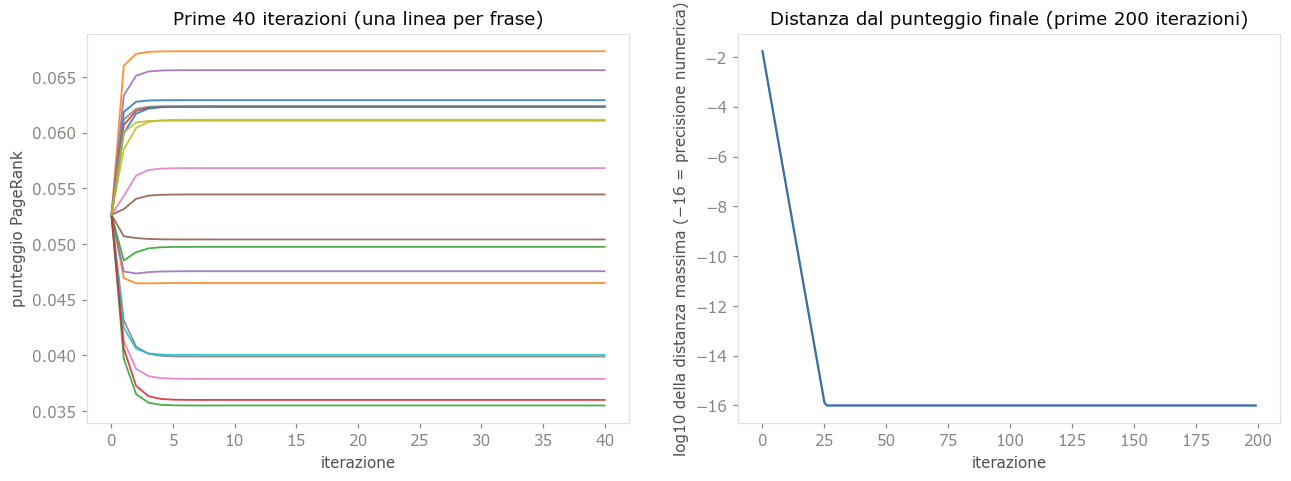

Distanza < 1e-10 già dopo 15 iterazioni su 1000.


In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6))
for i in range(N):
    a1.plot(range(0, 41), storia[:41, i], lw=1.2, alpha=.85)
a1.set_xlabel('iterazione'); a1.set_ylabel('punteggio PageRank'); a1.set_title('Prime 40 iterazioni (una linea per frase)')

dist = np.abs(storia - storia[-1]).max(axis=1)
a2.plot(np.log10(np.maximum(dist[:200], 1e-16)), color='#3b6ea5')
a2.set_xlabel('iterazione'); a2.set_ylabel('log10 della distanza massima (−16 = precisione numerica)')
a2.set_title('Distanza dal punteggio finale (prime 200 iterazioni)')
plt.show()
it_conv = int(np.argmax(dist < 1e-10))
print(f'Distanza < 1e-10 già dopo {it_conv} iterazioni su {N_ITER}.')

### I punteggi finali
Un punteggio più alto = frase più **centrale** nel grafo.

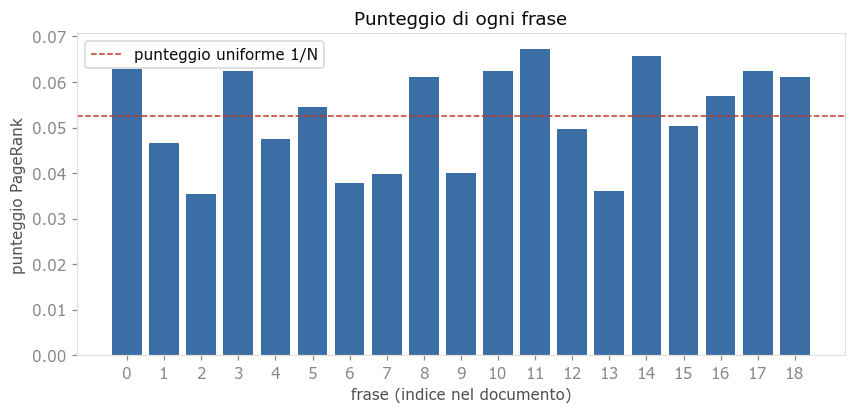

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(range(N), rank, color='#3b6ea5')
ax.set_xticks(range(N)); ax.set_xlabel('frase (indice nel documento)'); ax.set_ylabel('punteggio PageRank')
ax.axhline(1 / N, color='#c0392b', ls='--', lw=1, label='punteggio uniforme 1/N')
ax.legend(); ax.set_title('Punteggio di ogni frase')
plt.show()

**Cosa abbiamo visto.** Il punteggio sopra la linea tratteggiata indica una frase *più centrale
della media*. Notare che i punteggi di frasi diverse possono essere molto vicini: il ranking è
meno "netto" di quanto sembri, soprattutto con il grafo denso.

## 8. Selezione delle frasi più rilevanti
Si ordinano le frasi per punteggio **decrescente**; poi la `MODALITA` decide dove fermarsi:

- **`'frasi'`**: si tengono le prime `N_SENTENCES = 11` (valore del benchmark: 11 è la mediana
  del numero di frasi dei riassunti del corpus);
- **`'budget'`**: si accumulano frasi **nello stesso ordine** finché si raggiunge il **budget**
  = lunghezza in parole del riferimento (`su.seleziona_per_budget`: la frase che sfora viene
  inclusa solo se ne entra più della metà). Si usa solo la *lunghezza* del gold, mai il suo
  contenuto.

In entrambi i casi il ranking è lo stesso: cambia solo il punto di taglio. Il numero di frasi
— cioè la **lunghezza** — è un parametro *esterno* all'algoritmo.

MODALITA = 'budget': selezionate 3 frasi (190 parole) | budget = 168 parole


,frase,punteggio,parole,scelta,testo
posizione,,,,,
1,11,0.06732,62,✔,Now if Facebook will only reply to Richard’s query about why they removed my ori…
2,14,0.06563,68,✔,"Here is a report on the John Snow Kiss-In from the Guardian, featuring an interv…"
3,0,0.06293,60,✔,"UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, becam…"
4,17,0.06240,13,,The page used a photo of two men kissing to promote the event…
5,3,0.06234,33,,"This picture has itself caused scandal in the UK, as it was a gay kiss that was …"
6,10,0.06233,61,,"Before it goes too far, I just want people to know that FB have NOT removed the …"
7,8,0.06117,37,,"Secondly, the removal of the Facebook John Snow Kiss-In event: \n \n It turns out …"
8,18,0.06108,68,,"According to NYULocal.com, the photo was quickly removed and the following e-mai…"
9,16,0.05683,25,,"We apologize for the inconvenience"" \n \n \n \n The Dangerous Minds Facebook page wa…"


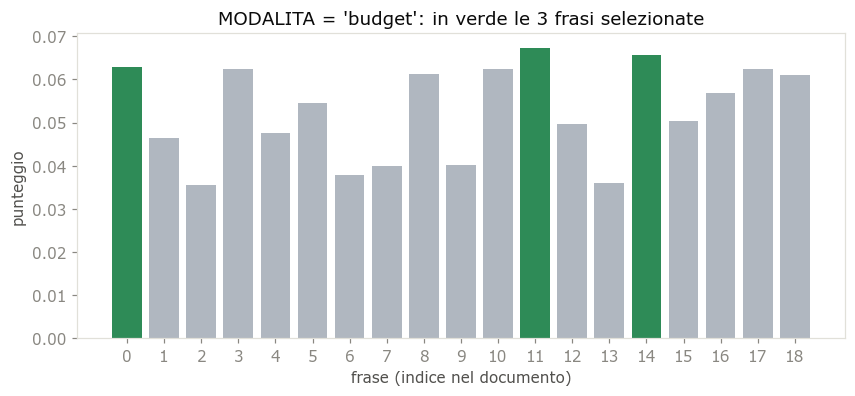

In [13]:
ordine = np.argsort(rank)[::-1]               # indici delle frasi, dalla più alla meno centrale

# le due regole di taglio, calcolate entrambe (servono al confronto delle sezioni 10-11)
budget = su.budget_riferimento(esempio)       # = parole del riferimento
idx_frasi = [int(i) for i in ordine[:N_SENTENCES]]
idx_budget = su.seleziona_per_budget(frasi, ordine, budget)
idx_scelti = idx_frasi if MODALITA == 'frasi' else idx_budget
selezionate = set(idx_scelti)
print(f"MODALITA = '{MODALITA}': selezionate {len(idx_scelti)} frasi "
      f"({sum(len(frasi[i].split()) for i in idx_scelti)} parole) | budget = {budget} parole")

classifica = pd.DataFrame({
    'posizione': range(1, N + 1),
    'frase': [int(i) for i in ordine],
    'punteggio': [round(float(rank[i]), 5) for i in ordine],
    'parole': [len(frasi[i].split()) for i in ordine],
    'scelta': ['✔' if int(i) in selezionate else '' for i in ordine],
    'testo': [frasi[i][:80] + '…' for i in ordine],
}).set_index('posizione')
display(classifica)

colori = ['#2e8b57' if i in selezionate else '#b0b7c0' for i in range(N)]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(N), rank, color=colori)
ax.set_xticks(range(N)); ax.set_xlabel('frase (indice nel documento)'); ax.set_ylabel('punteggio')
ax.set_title(f"MODALITA = '{MODALITA}': in verde le {len(selezionate)} frasi selezionate")
plt.show()

**Cosa abbiamo visto.** Le frasi scelte sono sparse nel documento: nessun criterio di
*posizione* (come invece avviene nel baseline First-k) ma solo di centralità.

## 9. Generazione del riassunto finale
Il riassunto è la concatenazione delle frasi **originali** scelte. In modalità `'budget'` si
applica poi il **tetto**: troncamento alle prime `round(1,25 × lunghezza del riferimento)`
parole (`su.tetto_riferimento`), come fa il benchmark prima di calcolare le metriche. L'ordine di emissione di
`show_summary` della libreria è quello **per punteggio decrescente** (non l'ordine in cui le frasi
compaiono nel documento): lo replichiamo e verifichiamo che coincida. In basso, per confronto, la
stessa selezione rimessa **in ordine di documento** (spesso più leggibile, ma non è ciò che il
benchmark valuta; ROUGE comunque lo ignora, essendo basato su insiemi di n-grammi).

In [14]:
tetto = su.tetto_riferimento(esempio)         # round(1,25 × riferimento)

riassunto_frasi = ' '.join(frasi[i] for i in idx_frasi)
assert riassunto_frasi == s.show_summary(rank, n=N_SENTENCES)   # identico alla libreria
riassunto_budget = ' '.join(frasi[i] for i in idx_budget)
riassunto_budget_tetto = su.tronca_parole(riassunto_budget, tetto)

riassunto = riassunto_frasi if MODALITA == 'frasi' else riassunto_budget_tetto   # ← quello che si valuta
print(f"✔ La modalità 'frasi' è identica a s.show_summary(rank, n={N_SENTENCES})")
if MODALITA == 'budget':
    print(f'  budget = {budget} parole | tetto = {tetto} parole | prima del tetto: {len(riassunto_budget.split())} parole')
print(f"\nRIASSUNTO — MODALITA '{MODALITA}' ({len(riassunto.split())} parole, ordine per punteggio):\n")
print(textwrap.fill(riassunto, 110))

riassunto_doc = ' '.join(frasi[i] for i in sorted(idx_scelti))
print(f'\n--- stessa selezione in ordine di documento ---\n')
print(textwrap.fill(riassunto_doc, 110))

✔ La modalità 'frasi' è identica a s.show_summary(rank, n=11)
  budget = 168 parole | tetto = 210 parole | prima del tetto: 190 parole

RIASSUNTO — MODALITA 'budget' (190 parole, ordine per punteggio):

Now if Facebook will only reply to Richard’s query about why they removed my original post and photo when he
put it up on his wall…     It has been erroneously reported in the media that our own Richard Metzger (who
lives in Los Angeles) organized the London “Kiss-In” event, which is untrue, and also unfair to Paul Shetler
and the actual organizers Here is a report on the John Snow Kiss-In from the Guardian, featuring an interview
with Mr Shetler: || News ||     Page 1 of 1             UPDATED: A photo of two men kissing that was posted on
a Facebook page protesting a London pub’s decision to eject a same-sex couple for kissing has been removed by
the social networking site, an error, according to a rep for the company UPDATE: 4/19/2001 Read Richard
Metzger: How I, a married, middle-age

**Cosa abbiamo visto.** Il riassunto è fatto di frasi copiate parola per parola: può contenere
**ridondanze** (due frasi molto simili entrambe centrali: TextRank/LexRank non hanno alcun
controllo anti-ridondanza, a differenza di MMR) e **riferimenti sospesi** ("he", "the company"
senza antecedente) perché le frasi sono state estratte dal loro contesto. Infine il testo grezzo
di Multi-News contiene **rumore di scraping** (menu del sito, "Page 1 of 1", "UPDATE: …"): se una
di queste righe risulta centrale, finisce nel riassunto.

## 10. Confronto con il riassunto di riferimento
Mettiamo a confronto il riassunto generato con quello umano e guardiamo le **lunghezze**
(la tabella mostra *entrambe* le modalità, la scelta è marcata da ◀): con 11 frasi fisse, TextRank/LexRank producono riassunti molto più lunghi del riferimento
(nel benchmark: ~368 e ~450 parole contro ~215). Questo è un **confondente di lunghezza**: un
riassunto più lungo ha più probabilità di contenere parole del riferimento, e quindi
*recall* più alta, indipendentemente dalla qualità della selezione.

Per questo il progetto ha introdotto la **rigenerazione a budget** (issue #16, protocollo
*length-matched*): il budget è la **lunghezza in parole del riferimento** (si usa solo la
*lunghezza* del gold, mai il suo contenuto). Si accumulano le frasi **nello stesso ordine di
ranking** finché si raggiunge il budget (`su.seleziona_per_budget`: la frase che sfora viene
inclusa solo se ne entra più della metà). Poi si applica il **tetto** a 1,25 × la lunghezza del
riferimento (`su.tetto_riferimento`), troncando alle prime parole.

Qui confrontiamo le versioni già calcolate nella sezione 9.

In [15]:
marca = {'frasi': ' ◀' if MODALITA == 'frasi' else '', 'budget': ' ◀' if MODALITA == 'budget' else ''}
lung = pd.DataFrame({
    'parole': [len(riferimento.split()), len(riassunto_frasi.split()), len(riassunto_budget.split()), len(riassunto_budget_tetto.split())],
    'frasi': ['—', len(idx_frasi), len(idx_budget), len(idx_budget)],
}, index=['riferimento umano', 'generato — 11 frasi' + marca['frasi'], 'generato — budget (prima del tetto)',
          'generato — budget + tetto' + marca['budget']])
lung['rapporto col riferimento'] = (lung['parole'] / len(riferimento.split())).round(2)
display(lung)
print(f'budget = {budget} parole | tetto = {tetto} parole')

print('\n=== RIFERIMENTO UMANO ===');            print(textwrap.fill(riferimento, 110))
print(f"\n=== GENERATO — MODALITA '{MODALITA}' ===");  print(textwrap.fill(riassunto, 110))

,parole,frasi,rapporto col riferimento
riferimento umano,168,—,1.00
generato — 11 frasi,477,11,2.84
generato — budget (prima del tetto),190,3,1.13
generato — budget + tetto ◀,190,3,1.13


budget = 168 parole | tetto = 210 parole

=== RIFERIMENTO UMANO ===
It turns out Facebook is only guilty of about half of what it’s been accused of in the gay kiss incident. The
social networking site apologized yesterday for taking down an image used to promote a “kiss-in” event in
London. “The photo in question does not violate our Statement of Rights and Responsibilities, and was removed
in error,” the site said in a statement, according to the Advocate. But Facebook did not, as has been reported
in several places, take down the kiss-in event itself. Here’s what happened: The photo Facebook took down was
posted by the Dangerous Minds blog to promote the event. In its initial write-up about the incident, the blog
observed that the page organizing the protest had been taken down. But it was actually the organizer himself
who "removed" the event, Dangerous Minds clarified. Organizer Paul Shetler explains that he decided to switch
it from a public event to a private one, as "there were 

**Cosa abbiamo visto.** Il riassunto a 11 frasi è tipicamente **molto più lungo** del
riferimento; quello a budget ha una lunghezza paragonabile (la tabella mostra entrambi). Il riferimento, inoltre, è *abstractive*: riformula,
sintetizza e ordina le informazioni in modo che nessuna frase estratta potrà mai riprodurre alla
lettera. Questo pone un **limite superiore** alle metriche di sovrapposizione per qualsiasi
metodo estrattivo.

## 11. Calcolo delle metriche di valutazione
Le metriche misurano la **sovrapposizione** tra riassunto generato e riferimento (testo
normalizzato: minuscole, senza punteggiatura, **con** stopword e numeri). Sono quelle di
`pyAutoSummarizer`, identiche per tutti i metodi del benchmark:

| metrica | cosa misura |
|---|---|
| **ROUGE-1 / ROUGE-2** | sovrapposizione di unigrammi / bigrammi. **Precision** = quota degli n-grammi del generato presenti nel riferimento; **Recall** = quota degli n-grammi del riferimento ritrovati nel generato; **F1** = media armonica |
| **ROUGE-L** | sottosequenza comune più lunga (LCS), sensibile all'ordine delle parole |
| **BLEU** | precisione di n-grammi (1-4) con penalità di brevità |
| **METEOR** | corrispondenza di parole con penalità per la frammentazione dei match |

⚠️ **Caveat della libreria:** il ROUGE-N di `pyAutoSummarizer` usa **insiemi di n-grammi
unici** (non i conteggi *clipped* del ROUGE ufficiale): i valori sono confrontabili tra i metodi
di questo progetto ma **non** con quelli della letteratura.

Prima un calcolo di ROUGE-1 **a mano**, per vedere cosa c'è dentro i numeri.

In [16]:
valutatore = su.crea_valutatore()

def normalizza(testo):
    return valutatore.clear_text([testo], stop_words=[], lowercase=True, rmv_accents=False,
                                 rmv_special_chars=True, rmv_numbers=False, rmv_custom_words=[])[0].split()

def rouge1_a_mano(generato, rif):
    g, r = set(normalizza(generato)), set(normalizza(rif))     # insiemi di unigrammi UNICI
    comuni = g & r
    p, rec = len(comuni) / len(g), len(comuni) / len(r)
    return 2 * p * rec / (p + rec), p, rec, len(g), len(r), len(comuni)

f1, p, rec, ng, nr, nc = rouge1_a_mano(riassunto, riferimento)
print(f"Generato (MODALITA '{MODALITA}'): {ng} parole distinte | riferimento: {nr} parole distinte | in comune: {nc}")
print(f'precision = {nc}/{ng} = {p:.3f} | recall = {nc}/{nr} = {rec:.3f} | F1 = {f1:.3f}')

r1 = valutatore.rouge_N(riassunto, riferimento, n=1)          # (f1, precision, recall)
assert np.allclose([f1, p, rec], r1)
print('✔ Coincide con valutatore.rouge_N(…, n=1)')

Generato (MODALITA 'budget'): 130 parole distinte | riferimento: 103 parole distinte | in comune: 45
precision = 45/130 = 0.346 | recall = 45/103 = 0.437 | F1 = 0.386
✔ Coincide con valutatore.rouge_N(…, n=1)


Ora tutte le metriche, per il riassunto a **11 frasi** e per quello **a budget + tetto**
(le metriche dell'ambito `test_budgetref` del benchmark sono calcolate proprio sul testo dopo
il tetto). La colonna della modalità scelta è marcata da ◀; l'altra è lì per confronto.

,11 frasi,budget + tetto ◀
ROUGE-1 F1,0.406,0.386
ROUGE-1 precision,0.291,0.346
ROUGE-1 recall,0.670,0.437
ROUGE-2 F1,0.207,0.086
ROUGE-2 precision,0.143,0.081
ROUGE-2 recall,0.377,0.093
ROUGE-L F1,0.167,0.175
ROUGE-L precision,0.113,0.165
ROUGE-L recall,0.322,0.187
BLEU,0.112,0.041


C:\Users\maccu\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9664 (\N{BLACK LEFT-POINTING TRIANGLE}) missing from font(s) Verdana.
  fig.canvas.print_figure(bytes_io, **kw)


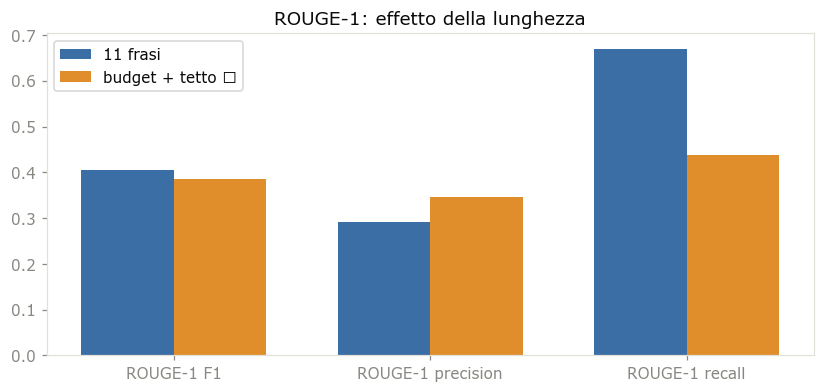

In [17]:
m11 = su.metriche_esempio(valutatore, riassunto_frasi, riferimento)
mbu = su.metriche_esempio(valutatore, riassunto_budget_tetto, riferimento)
m_scelta, m_altra = (m11, mbu) if MODALITA == 'frasi' else (mbu, m11)
assert np.isclose(m_scelta['rouge1_f1'], r1[0])   # coerente con il ROUGE-1 a mano della modalità scelta
et11 = '11 frasi' + (' ◀' if MODALITA == 'frasi' else '')
etbu = 'budget + tetto' + (' ◀' if MODALITA == 'budget' else '')

ordine_col = ['rouge1_f1', 'rouge1_p', 'rouge1_r', 'rouge2_f1', 'rouge2_p', 'rouge2_r',
              'rougeL_f1', 'rougeL_p', 'rougeL_r', 'bleu', 'meteor', 'parole_generate']
tab_metriche = pd.DataFrame({et11: m11, etbu: mbu}).loc[ordine_col]
tab_metriche.index = ['ROUGE-1 F1', 'ROUGE-1 precision', 'ROUGE-1 recall', 'ROUGE-2 F1', 'ROUGE-2 precision', 'ROUGE-2 recall',
                      'ROUGE-L F1', 'ROUGE-L precision', 'ROUGE-L recall', 'BLEU', 'METEOR', 'parole generate']
display(tab_metriche.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
chiavi = ['rouge1_f1', 'rouge1_p', 'rouge1_r']
x = np.arange(len(chiavi)); w = .36
ax.bar(x - w / 2, [m11[k] for k in chiavi], w, label=et11, color='#3b6ea5')
ax.bar(x + w / 2, [mbu[k] for k in chiavi], w, label=etbu, color='#e08e2b')
ax.set_xticks(x); ax.set_xticklabels(['ROUGE-1 F1', 'ROUGE-1 precision', 'ROUGE-1 recall'])
ax.legend(); ax.set_title('ROUGE-1: effetto della lunghezza')
plt.show()

**Cosa abbiamo visto.** Con più parole la **recall** sale (si "pescano" più parole del
riferimento) ma la **precision** scende (molte parole in più non servono): la **F1** compensa i
due effetti ed è la metrica più onesta quando le lunghezze sono diverse. A parità di lunghezza
(budget), la differenza tra metodi riflette davvero la qualità della *selezione dei contenuti*.

## 12. Interpretazione dei risultati
Il commento seguente legge i numeri **di questa riga** (si aggiorna se cambi `ROW_ID`).

In [18]:
nome_altra = 'budget + tetto' if MODALITA == 'frasi' else '11 frasi'
dr, db = m_altra['rouge1_r'] - m_scelta['rouge1_r'], m_altra['rouge1_p'] - m_scelta['rouge1_p']
testo = f"""
**Riga {ROW_ID} — TextRank — MODALITA `'{MODALITA}'`.**

- Il riassunto ha {m_scelta['parole_generate']} parole contro le {len(riferimento.split())} del riferimento
  ({m_scelta['parole_generate'] / len(riferimento.split()):.1f}×): ROUGE-1 recall = **{m_scelta['rouge1_r']:.3f}**,
  precision = **{m_scelta['rouge1_p']:.3f}**, F1 = **{m_scelta['rouge1_f1']:.3f}**.
- Per confronto, con la modalità *{nome_altra}* ({m_altra['parole_generate']} parole) la recall {'sale' if dr > 0 else 'scende'} a
  **{m_altra['rouge1_r']:.3f}** (Δ = {dr:+.3f}) e la precision {'sale' if db > 0 else 'scende'} a **{m_altra['rouge1_p']:.3f}**
  (Δ = {db:+.3f}): F1 = **{m_altra['rouge1_f1']:.3f}**.
- ROUGE-2 F1 = {m_scelta['rouge2_f1']:.3f} (modalità scelta): molto più bassa di ROUGE-1, perché le sequenze di **due parole**
  consecutive in comune col riferimento *astratto* sono rare — è tipico dei metodi estrattivi.
"""
display(Markdown(testo))


**Riga 50492 — TextRank — MODALITA `'budget'`.**

- Il riassunto ha 190 parole contro le 168 del riferimento
  (1.1×): ROUGE-1 recall = **0.437**,
  precision = **0.346**, F1 = **0.386**.
- Per confronto, con la modalità *11 frasi* (477 parole) la recall sale a
  **0.670** (Δ = +0.233) e la precision scende a **0.291**
  (Δ = -0.055): F1 = **0.406**.
- ROUGE-2 F1 = 0.086 (modalità scelta): molto più bassa di ROUGE-1, perché le sequenze di **due parole**
  consecutive in comune col riferimento *astratto* sono rare — è tipico dei metodi estrattivi.


### Cosa portarsi a casa
1. **TextRank è un ordinamento di frasi, non un riassunto "ragionato".** Produce un ranking di
   centralità; lunghezza, ordine e coerenza del testo finale sono scelte esterne.
2. **Il risultato dipende dalla matrice di similarità.** Con gli embedding la similarità è semantica (frasi parafrasate risultano vicine), costa una rete neurale per ogni frase.
3. **Niente anti-ridondanza né coerenza**: possono essere scelte frasi quasi duplicate (specie in
   un cluster di articoli sulla stessa notizia, dove molte frasi si assomigliano per costruzione).
4. **La lunghezza è un confondente.** Il confronto onesto tra metodi si fa a lunghezza uguale
   (*length-matched*): nel benchmark a 5.588 righe di test, TextRank: ROUGE-1 F1 0,370 (11 frasi, ~368 parole) → 0,359 (budget, ~215 parole); il calo è piccolo ma ora è
   un confronto alla pari.
5. **Il tetto delle metriche estrattive.** Il riferimento è astratto; le frasi estratte non lo
   riprodurranno mai: ecco perché i metodi abstractive (PEGASUS, PRIMERA) e gli LLM stanno
   sopra in ROUGE.

### Esercizi proposti
- Cambia `ROW_ID` (es. 50501, 50523) e osserva come cambiano heatmap, grafo e selezione.
- Passa `MODALITA` da `'frasi'` a `'budget'` (sezione 1) e rileggi le sezioni 8-12. Poi, con `'frasi'`, prova `N_SENTENCES = 5` e `3`: come si muovono precision, recall e F1?
- Nella sezione 7 imposta `D = 0.5` o `D = 0.99`: i punteggi diventano più uniformi o più
  polarizzati? E la selezione cambia?
- Nella sezione 6 abbassa/alza il percentile della vista B: quanti cluster di frasi riesci a
  distinguere?